# Autoportrait 3 — extraction avec la consigne B (Qwen3-32B)

Ce carnet constitue la **troisième phase** : il applique [la consigne B](consigne_B_extraction.md) aux mêmes chansons que le carnet A, en lisant directement son export `autoportrait2_qwen_description_{n}.csv`. Les `source_row_index` sont relus dans `corpus.csv` et les artistes/titres sont vérifiés. Les erreurs d’annotation A restent dans le périmètre : la sélection reproduit exactement les lignes de son export.

Le serveur vLLM doit être lancé sur **un seul GPU** et un seul endpoint. Le carnet ne démarre pas le serveur. Avant de le lancer, examiner `nvidia-smi`, choisir un GPU libre sans interrompre les processus d’autres utilisateurs, puis démarrer le serveur avec `CUDA_VISIBLE_DEVICES=<GPU_PHYSIQUE>` et `--reasoning-parser qwen3`. Par exemple :

```bash
nvidia-smi
CUDA_VISIBLE_DEVICES=<GPU_PHYSIQUE> vllm serve Qwen/Qwen3-32B --reasoning-parser qwen3 --max-num-seqs 12 --port 8018
```

Configurer `QWEN_BASE_URL=http://127.0.0.1:8018/v1` et, facultativement, `QWEN_GPU=<GPU_PHYSIQUE>`. Le carnet refuse une liste de plusieurs endpoints et vérifie que le modèle attendu est servi. La progression affiche débit et ETA estimée à partir des réponses déjà reçues ; les métriques sont côté client (pas une mesure CUDA directe).

L’export A existant de 8 861 lignes est le réglage par défaut. Le réglage initial est un pilote reproductible de 10 chansons ; vérifier les JSON/CSV et la couverture, puis passer `taille_echantillon = None` pour traiter **tout le même export A**. Les sorties de tailles différentes ne s’écrasent pas.

In [3]:
# ====================== PARAMÈTRES À RÉGLER ======================
# Taille de l’export du carnet consigne A à relire. Exemple disponible : 8861.
n_source_A = 8861
# Pilote déterministe ; mettre None après validation pour tout l’export A.
taille_echantillon = None
graine = 42
# Concurrence sur l’unique serveur/GPU ; ne pas dépasser --max-num-seqs du serveur.
workers_gpu = 48
max_num_seqs_serveur = 48
# Lot d’ordonnancement : borne le nombre de tâches en mémoire.
taille_lot = 128
# ================================================================

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from IPython.display import display
import fcntl
import hashlib
import importlib.util
import json
import os
import time
import urllib.error
import urllib.request

import pandas as pd
from tqdm.auto import tqdm

candidats = [Path.cwd(), Path.cwd() / "Autoportrait", Path.cwd() / "Rap" / "Autoportrait"]
dossiers = [p.resolve() for p in candidats if (p / "consigne_B_extraction.md").is_file() and (p / "annoter.py").is_file()]
if len(dossiers) != 1:
    raise RuntimeError("Lancer le carnet depuis la racine du dépôt, Rap ou Rap/Autoportrait.")
dossier = dossiers[0]
corpus_path = dossier.parent / "corpus.csv"
consigne_path = dossier / "consigne_B_extraction.md"
schema_path = dossier / "schema_B_extraction.json"
resultats_dir = dossier / "data" / "results"
performance_dir = dossier / "data" / "performance"
source_path = resultats_dir / f"autoportrait2_qwen_description_{n_source_A}.csv"
cumul_path = performance_dir / "perfGPU_autoportrait3.csv"

base_url = os.environ.get("QWEN_BASE_URL", "http://127.0.0.1:8018/v1").strip().rstrip("/")
if "," in base_url or not base_url.startswith(("http://", "https://")):
    raise ValueError("QWEN_BASE_URL doit contenir l’URL d’un seul serveur vLLM.")
gpu_physique = os.environ.get("QWEN_GPU", "non renseigné")
modele = "Qwen/Qwen3-32B"
cle_api = os.environ.get("QWEN_API_KEY", "EMPTY")
timeout_secondes = 600
max_tokens = 2048
enable_thinking = True
max_essais = 2

if type(n_source_A) is not int or n_source_A <= 0:
    raise ValueError("n_source_A doit être un entier positif.")
if taille_echantillon is not None and (type(taille_echantillon) is not int or taille_echantillon <= 0):
    raise ValueError("taille_echantillon doit être un entier positif ou None.")
if type(workers_gpu) is not int or type(max_num_seqs_serveur) is not int or not 1 <= workers_gpu <= max_num_seqs_serveur:
    raise ValueError("workers_gpu doit être entre 1 et max_num_seqs_serveur.")
if type(taille_lot) is not int or taille_lot <= 0:
    raise ValueError("taille_lot doit être un entier positif.")

spec = importlib.util.spec_from_file_location("autoportrait_source", dossier / "annoter.py")
if spec is None or spec.loader is None:
    raise ImportError("Impossible de charger annoter.py.")
source = importlib.util.module_from_spec(spec)
spec.loader.exec_module(source)
consigne = consigne_path.read_text(encoding="utf-8").strip()
schema = json.loads(schema_path.read_text(encoding="utf-8"))
if not consigne or schema.get("type") != "object":
    raise ValueError("Consigne B ou schéma B vide/invalide.")
champs = schema["required"]
if champs != ["outils", "noms", "comparaisons"] or set(champs) != set(schema["properties"]):
    raise ValueError("Structure inattendue pour schema_B_extraction.json.")
print("Dossier :", dossier)
print("Source A :", source_path.name, "| serveur unique :", base_url, "| GPU déclaré :", gpu_physique)
print("Modèle :", modele, "| workers :", workers_gpu, "| pilote :", taille_echantillon)
print("Champs B :", champs)

Dossier : /home/cbenavent/test/Rap/Autoportrait
Source A : autoportrait2_qwen_description_8861.csv | serveur unique : http://127.0.0.1:8018/v1 | GPU déclaré : non renseigné
Modèle : Qwen/Qwen3-32B | workers : 48 | pilote : None
Champs B : ['outils', 'noms', 'comparaisons']


## 1. Chargement du même ensemble que la consigne A

La source est l’export complet du carnet A, y compris les lignes dont l’annotation A a échoué. Les paroles sont relues à partir de `source_row_index` et nettoyées par le helper commun. Si `taille_echantillon` est un entier, le pilote est tiré de cet ensemble avec la graine fixe ; `None` conserve toutes les lignes, dans leur ordre d’origine. Cette étape ne lance aucune inférence.

In [4]:
if not source_path.is_file():
    disponibles = sorted(int(p.stem.rsplit("_", 1)[1]) for p in resultats_dir.glob("autoportrait2_qwen_description_*.csv")
                         if p.stem.rsplit("_", 1)[1].isdigit())
    raise FileNotFoundError(f"{source_path.name} absent. Exports A disponibles : {disponibles}")
phase_A = pd.read_csv(source_path, dtype={"annee": "string"}, keep_default_na=False, encoding="utf-8-sig")
colonnes_requises = {"source_row_index", "artiste", "titre", "annee", "statut"}
if not colonnes_requises <= set(phase_A.columns):
    raise ValueError(f"Colonnes absentes de l’export A : {sorted(colonnes_requises - set(phase_A.columns))}")
if phase_A.empty or phase_A["source_row_index"].duplicated().any():
    raise ValueError("L’export A est vide ou contient des source_row_index en double.")
if len(phase_A) != n_source_A:
    raise ValueError(f"L’export {source_path.name} contient {len(phase_A)} lignes, attendu : {n_source_A}.")
phase_A["source_row_index"] = pd.to_numeric(phase_A["source_row_index"], errors="raise").astype("int64")
if phase_A["source_row_index"].duplicated().any():
    raise ValueError("source_row_index en double après conversion numérique.")
ids_source = set(phase_A["source_row_index"].tolist())
textes = source.lire_corpus(corpus_path, ids_source)
chansons = []
for ligne in tqdm(phase_A.itertuples(index=False), total=len(phase_A), desc="Relecture des paroles", unit="chansons"):
    position = int(ligne.source_row_index)
    texte = textes.get(position)
    if texte is None or (texte["artiste"], texte["titre"]) != (ligne.artiste, ligne.titre):
        raise RuntimeError(f"Chanson {position} absente ou différente : corpus.csv a-t-il changé depuis A ?")
    paroles = source.nettoyer(texte["paroles"])
    if not paroles:
        raise RuntimeError(f"Paroles vides après nettoyage pour la chanson {position}.")
    chansons.append({"source_row_index": position, "artiste": ligne.artiste, "titre": ligne.titre,
                     "annee": ligne.annee, "statut_A": ligne.statut,
                     "justification_A": getattr(ligne, "justification", ""), "paroles": paroles})

if taille_echantillon is None:
    selection = chansons
    perimetre = "complet"
else:
    if taille_echantillon > len(chansons):
        raise ValueError(f"Le pilote demandé ({taille_echantillon}) dépasse les {len(chansons)} lignes A.")
    indices = sorted(pd.Series(range(len(chansons))).sample(n=taille_echantillon, random_state=graine).tolist())
    selection = [chansons[i] for i in indices]
    perimetre = f"pilote_{taille_echantillon}"
print(f"Export A : {len(chansons)} chansons ; sélection B : {len(selection)} ; périmètre : {perimetre}.")
print("Statuts A :", phase_A["statut"].value_counts(dropna=False).to_dict())
print("Aucune inférence lancée.")
display(pd.DataFrame(selection)[["source_row_index", "artiste", "titre", "annee", "statut_A"]].head(10))

Relecture des paroles:   0%|          | 0/8861 [00:00<?, ?chansons/s]

Export A : 8861 chansons ; sélection B : 8861 ; périmètre : complet.
Statuts A : {'ok': 8819, 'erreur': 42}
Aucune inférence lancée.


,source_row_index,artiste,titre,annee,statut_A
0,0,Dry,94310,2012,ok
1,5,Lynda,A ma place,2014,ok
2,18,PLK,1€ / 1Eu,2024,ok
3,19,PLK,Une pêche une patate,2024,ok
4,29,Rim’K,Jour de pluie,2024,ok
5,53,Zamdane,Printemps,2024,ok
6,55,orphevre,L’EAU QUI DORT,2022,ok
7,68,S-Tee (FRA),TERRAIN VAGUE,2024,ok
8,69,S-Tee (FRA),TRAP À LA MORT,2024,ok
9,86,Battso,Avengers (il faut sauver le Rap Français),2014,ok


## 2. Client vLLM, validation et annotation

Chaque requête envoie les paroles nettoyées et la consigne B en message système. Le JSON Schema strict est imposé côté vLLM, puis chaque champ est revalidé côté client (clés exactes, types, catégories autorisées, mentions uniques). Une réponse réussie doit être complète (`finish_reason == "stop"`) et inclure un raisonnement Qwen non vide. Les erreurs techniques sont conservées et retentées à la relance.

Le carnet n’utilise qu’un serveur ; réglez `workers_gpu` au plus à `--max-num-seqs` du serveur. La cellule d’exécution vérifie `/v1/models` avant l’inférence. Le journal JSONL est synchronisé après chaque réponse pour permettre la reprise.

In [17]:
ouvreur = urllib.request.build_opener(urllib.request.ProxyHandler({}))

def appeler_api(route, corps=None):
    requete = urllib.request.Request(base_url + route,
        data=None if corps is None else json.dumps(corps).encode("utf-8"),
        headers={"Content-Type": "application/json", "Authorization": f"Bearer {cle_api}"})
    with ouvreur.open(requete, timeout=timeout_secondes) as reponse:
        return json.loads(reponse.read().decode("utf-8"))

def verifier_serveur():
    try:
        reponse = appeler_api("/models")
    except urllib.error.HTTPError as exc:
        raise RuntimeError(f"HTTP {exc.code} sur {base_url}/models ; vérifier le serveur et la clé API.") from exc
    except (urllib.error.URLError, OSError) as exc:
        raise RuntimeError(f"Serveur vLLM injoignable sur {base_url}. Le notebook ne le démarre pas.") from exc
    modeles = [item["id"] for item in reponse.get("data", [])]
    if modele not in modeles:
        raise RuntimeError(f"{modele} absent sur {base_url}. Modèles servis : {modeles}")
    print("Serveur prêt :", base_url, "|", modele, "| GPU déclaré :", gpu_physique)

def valider_objet(objet, schema_objet, chemin="réponse"):
    if not isinstance(objet, dict) or set(objet) != set(schema_objet["required"]):
        raise ValueError(f"{chemin} : clés attendues {schema_objet['required']}.")
    resultat = {}
    for nom, regle in schema_objet["properties"].items():
        valeur = objet[nom]
        if regle["type"] == "array":
            if not isinstance(valeur, list):
                raise ValueError(f"{chemin}.{nom} doit être une liste.")
            items = []
            noms_vus = set()
            for index, item in enumerate(valeur):
                item_schema = regle["items"]
                if not isinstance(item, dict) or set(item) != set(item_schema["required"]):
                    raise ValueError(f"{chemin}.{nom}[{index}] : clés invalides.")
                for champ, champ_schema in item_schema["properties"].items():
                    champ_valeur = item[champ]
                    attendu = champ_schema["type"]
                    type_ok = (isinstance(champ_valeur, str) if attendu == "string" else
                               isinstance(champ_valeur, bool) if attendu == "boolean" else False)
                    if not type_ok or (attendu == "string" and not champ_valeur.strip()):
                        raise ValueError(f"{chemin}.{nom}[{index}].{champ} : valeur vide ou type invalide.")
                    if "enum" in champ_schema and champ_valeur not in champ_schema["enum"]:
                        raise ValueError(f"{chemin}.{nom}[{index}].{champ} : modalité inconnue {champ_valeur!r}.")
                mention = item["mention"]
                if mention in noms_vus:
                    raise ValueError(f"{chemin}.{nom} contient la mention répétée {mention!r}.")
                noms_vus.add(mention)
                if mention not in item["extrait"]:
                    raise ValueError(f"{chemin}.{nom} : la mention n’apparaît pas dans son extrait.")
                items.append(item)
            resultat[nom] = items
        else:
            raise ValueError(f"Type de champ racine inattendu : {nom}.")
    return resultat

def valider_reponse(reponse):
    choix = reponse["choices"][0]
    if choix.get("finish_reason") != "stop":
        raise ValueError(f"Génération incomplète : {choix.get('finish_reason')!r}")
    message = choix["message"]
    contenu = message.get("content")
    raisonnement = message.get("reasoning") or message.get("reasoning_content") or ""
    if not isinstance(contenu, str) or not contenu.strip():
        raise ValueError("Contenu JSON absent ou vide.")
    if enable_thinking and (not isinstance(raisonnement, str) or not raisonnement.strip()):
        raise ValueError("Raisonnement Qwen absent ; vérifier --reasoning-parser qwen3.")
    return {**valider_objet(json.loads(contenu), schema), "raisonnement": raisonnement.strip()}

def extraction_vide():
    return {"outils": [], "noms": [], "comparaisons": [], "raisonnement": ""}

def annoter_chanson(chanson):
    debut = time.perf_counter()
    corps = {"model": modele,
        "messages": source.messages(consigne, chanson["paroles"], False),
        "temperature": 0, "seed": graine, "max_tokens": max_tokens,
        "chat_template_kwargs": {"enable_thinking": enable_thinking},
        "response_format": {"type": "json_schema", "json_schema": {"name": "extraction_autoportrait",
                           "schema": schema, "strict": True}}}
    erreur = ""
    for essai in range(1, max_essais + 1):
        try:
            resultat = valider_reponse(appeler_api("/chat/completions", corps))
            return {**resultat, "statut": "ok", "erreur": "", "essais": essai,
                    "secondes": time.perf_counter() - debut, "serveur": base_url}
        except urllib.error.HTTPError as exc:
            erreur = f"HTTP {exc.code} : {exc.read().decode('utf-8', 'replace')[:1000]}"
            if exc.code not in {408, 429, 500, 502, 503, 504}:
                break
        except (urllib.error.URLError, OSError, ValueError, KeyError, IndexError, TypeError) as exc:
            erreur = f"{type(exc).__name__} : {exc}"
        if essai < max_essais:
            time.sleep(2 * essai)
    return {**extraction_vide(), "statut": "erreur", "erreur": erreur,
            "essais": essai, "secondes": time.perf_counter() - debut, "serveur": base_url}

## 3. Journal, reprise, progression et exports

Les noms incluent la taille et le périmètre (pilote ou complet). Les réussites du journal compatible sont reprises ; seules les erreurs sont retentées. Les listes JSON restent intactes dans le CSV principal et sont aussi normalisées en une ligne par extraction dans le fichier `_elements.csv`. Les fréquences donnent le nombre d’occurrences et le nombre de chansons distinctes. Les paroles ne sont jamais exportées.

In [18]:
def empreinte_pipeline():
    configuration = {"version": 1, "tache": "consigne_B_extraction", "modele": modele,
        "serveur": base_url, "consigne": consigne, "schema": schema,
        "source_A": source_path.name, "source_A_sha256": hashlib.sha256(source_path.read_bytes()).hexdigest(),
        "selection": [c["source_row_index"] for c in selection], "temperature": 0,
        "seed": graine, "max_tokens": max_tokens, "enable_thinking": enable_thinking}
    return hashlib.sha256(json.dumps(configuration, ensure_ascii=False, sort_keys=True).encode()).hexdigest()

def tableau_export(lignes):
    tableau = pd.DataFrame(lignes)
    for champ in champs:
        tableau[champ] = tableau[champ].map(lambda valeur: json.dumps(valeur, ensure_ascii=False))
    return tableau

def aplatir_elements(resultats):
    lignes = []
    for r in resultats:
        commun = {"source_row_index": r["source_row_index"], "artiste": r["artiste"],
                  "titre": r["titre"], "annee": r["annee"]}
        for item in r["outils"]:
            lignes.append({**commun, "type_element": "outil", "categorie": item["categorie"],
                "mention": item["mention"], "reference": "", "sens": "",
                "arme": item["arme"], "extrait": item["extrait"]})
        for item in r["noms"]:
            lignes.append({**commun, "type_element": "nom", "categorie": item["type"],
                "mention": item["mention"], "reference": "", "sens": "",
                "arme": "", "extrait": item["extrait"]})
        for item in r["comparaisons"]:
            lignes.append({**commun, "type_element": "comparaison", "categorie": "",
                "mention": item["mention"], "reference": item["reference"],
                "sens": item["sens"], "arme": "", "extrait": item["extrait"]})
    colonnes = ["source_row_index", "artiste", "titre", "annee", "type_element",
                "categorie", "mention", "reference", "sens", "arme", "extrait"]
    return pd.DataFrame(lignes, columns=colonnes)

def executer_extraction():
    resultats_dir.mkdir(parents=True, exist_ok=True)
    performance_dir.mkdir(parents=True, exist_ok=True)
    signature = empreinte_pipeline()
    n = len(selection)
    suffixe = f"{n}"
    prefixe = f"autoportrait3_qwen_extraction_{suffixe}"
    journal = resultats_dir / f"autoportrait3_qwen32_reason_{perimetre}_n{n}_{signature[:12]}.jsonl"
    ids = [c["source_row_index"] for c in selection]
    ids_set = set(ids)
    debut_session = time.perf_counter()
    with (resultats_dir / f"{prefixe}.lock").open("a") as verrou:
        try:
            fcntl.flock(verrou, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError as exc:
            raise RuntimeError("Un traitement de même taille écrit déjà ces exports.") from exc
        cache = {}
        if journal.exists():
            with journal.open(encoding="utf-8") as fichier:
                for numero, ligne in enumerate(fichier, 1):
                    try:
                        resultat = json.loads(ligne)
                    except json.JSONDecodeError as exc:
                        raise ValueError(f"Journal endommagé, ligne {numero} : {journal}") from exc
                    if resultat.get("empreinte") != signature or resultat.get("source_row_index") not in ids_set:
                        raise ValueError("Journal incompatible avec la sélection courante.")
                    if resultat.get("statut") not in {"ok", "erreur"}:
                        raise ValueError("Statut invalide dans le journal.")
                    if resultat["statut"] == "ok":
                        valide = valider_objet({k: resultat[k] for k in champs}, schema)
                        if not resultat.get("raisonnement", "").strip():
                            raise ValueError("Raisonnement absent d’une réussite du journal.")
                        resultat.update(valide)
                    cache[resultat["source_row_index"]] = resultat
        restantes = [c for c in selection if cache.get(c["source_row_index"], {}).get("statut") != "ok"]
        reprises = n - len(restantes)
        print(f"{reprises} réussites reprises ; {len(restantes)} chansons à annoter.")
        if restantes:
            verifier_serveur()
        traitees = erreurs = 0
        with journal.open("a", encoding="utf-8") as fichier:
            with ThreadPoolExecutor(max_workers=workers_gpu) as executeur:
                futures_actives = set()
                try:
                    with tqdm(total=n, initial=reprises, desc="Extraction consigne B", unit="chansons",
                              dynamic_ncols=True, mininterval=0.5) as barre:
                        for debut_lot in range(0, len(restantes), taille_lot):
                            lot = restantes[debut_lot:debut_lot + taille_lot]
                            futures = {executeur.submit(annoter_chanson, c): c for c in lot}
                            futures_actives = set(futures)
                            for future in as_completed(futures):
                                chanson = futures[future]
                                resultat = {**{k: v for k, v in chanson.items() if k != "paroles"},
                                    **future.result(), "modele": modele, "empreinte": signature,
                                    "date_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
                                fichier.write(json.dumps(resultat, ensure_ascii=False) + "\n")
                                fichier.flush()
                                os.fsync(fichier.fileno())
                                cache[chanson["source_row_index"]] = resultat
                                traitees += 1
                                erreurs += resultat["statut"] == "erreur"
                                barre.update(1)
                                debit = traitees / max(time.perf_counter() - debut_session, 1e-9)
                                barre.set_postfix(erreurs=erreurs, chansons_s=f"{debit:.2f}", refresh=False)
                except BaseException:
                    for future in futures_actives:
                        future.cancel()
                    raise
        ordonnes = [cache[position] for position in ids]
        if len(ordonnes) != n:
            raise RuntimeError("Effectif final différent de la sélection.")
        tableau = tableau_export(ordonnes)
        tableau.to_csv(resultats_dir / f"{prefixe}.csv", index=False, encoding="utf-8-sig")
        (resultats_dir / f"{prefixe}.json").write_text(json.dumps(ordonnes, ensure_ascii=False, indent=2), encoding="utf-8")
        tableau.loc[tableau["statut"] == "erreur"].to_csv(resultats_dir / f"{prefixe}_erreurs.csv", index=False, encoding="utf-8-sig")
        valides = [r for r in ordonnes if r["statut"] == "ok"]
        elements = aplatir_elements(valides)
        elements.to_csv(resultats_dir / f"{prefixe}_elements.csv", index=False, encoding="utf-8-sig")
        if elements.empty:
            distributions = pd.DataFrame(columns=["type_element", "categorie", "effectif", "chansons", "pourcentage_chansons"])
            frequences = pd.DataFrame(columns=["type_element", "categorie", "mention", "reference", "sens", "arme", "effectif", "chansons", "pourcentage_chansons"])
        else:
            denominateur = max(len(valides), 1)
            distributions = (elements.groupby(["type_element", "categorie"], dropna=False, sort=False)
                .agg(effectif=("source_row_index", "size"), chansons=("source_row_index", "nunique")).reset_index())
            distributions["pourcentage_chansons"] = (100 * distributions["chansons"] / denominateur).round(1)
            frequences = (elements.groupby(["type_element", "categorie", "mention", "reference", "sens", "arme"], dropna=False, sort=False)
                .agg(effectif=("source_row_index", "size"), chansons=("source_row_index", "nunique")).reset_index())
            frequences["pourcentage_chansons"] = (100 * frequences["chansons"] / denominateur).round(1)
            frequences = frequences.sort_values(["type_element", "chansons", "effectif", "mention"], ascending=[True, False, False, True])
        distributions.to_csv(resultats_dir / f"{prefixe}_distributions.csv", index=False, encoding="utf-8-sig")
        frequences.to_csv(resultats_dir / f"{prefixe}_frequences.csv", index=False, encoding="utf-8-sig")
        duree = time.perf_counter() - debut_session
        metriques = {"date_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
            "modele": modele, "gpu_physique_declare": gpu_physique, "serveur": base_url,
            "perimetre": perimetre, "n": n, "reprises": reprises, "traitees_session": traitees,
            "reussites": len(valides), "erreurs": int((tableau["statut"] == "erreur").sum()),
            "duree_client_secondes": round(duree, 3), "chansons_par_seconde": round(traitees / max(duree, 1e-9), 4),
            "workers_gpu": workers_gpu, "taille_lot": taille_lot, "max_tokens": max_tokens,
            "extractions_outils": sum(len(r["outils"]) for r in valides),
            "extractions_noms": sum(len(r["noms"]) for r in valides),
            "extractions_comparaisons": sum(len(r["comparaisons"]) for r in valides)}
        with cumul_path.open("a+", encoding="utf-8", newline="") as fichier_perf:
            fcntl.flock(fichier_perf, fcntl.LOCK_EX)
            fichier_perf.seek(0, os.SEEK_END)
            vide = fichier_perf.tell() == 0
            pd.DataFrame([metriques]).to_csv(fichier_perf, index=False, header=vide)
            fichier_perf.flush()
            os.fsync(fichier_perf.fileno())
    display(pd.DataFrame([metriques]))
    print("CSV principal :", resultats_dir / f"{prefixe}.csv")
    print("Éléments normalisés :", resultats_dir / f"{prefixe}_elements.csv")
    print("Fréquences :", resultats_dir / f"{prefixe}_frequences.csv")
    if metriques["erreurs"]:
        print("ATTENTION : erreurs techniques présentes ; relancer cette cellule pour reprendre les erreurs.")
    return ordonnes, tableau, elements, distributions, frequences

verifier_serveur()
extractions, resultats, elements, distributions, frequences = executer_extraction()
display(resultats[["source_row_index", "artiste", "titre", "statut", "outils", "noms", "comparaisons", "erreur"]].head(10))
print("Répartition des catégories :")
display(distributions)
if not resultats["statut"].eq("ok").all():
    raise RuntimeError("Lot incomplet : consulter le CSV erreurs et relancer pour reprendre.")

Serveur prêt : http://127.0.0.1:8018/v1 | Qwen/Qwen3-32B | GPU déclaré : non renseigné
0 réussites reprises ; 8861 chansons à annoter.
Serveur prêt : http://127.0.0.1:8018/v1 | Qwen/Qwen3-32B | GPU déclaré : non renseigné


Extraction consigne B:   0%|          | 0/8861 [00:00<?, ?chansons/s]

,date_utc,modele,gpu_physique_declare,serveur,perimetre,n,reprises,traitees_session,reussites,erreurs,duree_client_secondes,chansons_par_seconde,workers_gpu,taille_lot,max_tokens,extractions_outils,extractions_noms,extractions_comparaisons
0,2026-11-05T22:03:14Z,Qwen/Qwen3-32B,non renseigné,http://127.0.0.1:8018/v1,complet,8861,0,8861,6610,2251,8634.652,1.0262,48,128,2048,7975,10068,7744


CSV principal : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait3_qwen_extraction_8861.csv
Éléments normalisés : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait3_qwen_extraction_8861_elements.csv
Fréquences : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait3_qwen_extraction_8861_frequences.csv
ATTENTION : erreurs techniques présentes ; relancer cette cellule pour reprendre les erreurs.


,source_row_index,artiste,titre,statut,outils,noms,comparaisons,erreur
0,0,Dry,94310,ok,"[{""categorie"": ""oral"", ""mention"": ""MIC"", ""arme...","[{""type"": ""nom_de_scene"", ""mention"": ""S.T.O.K....","[{""mention"": ""Fian-so"", ""reference"": ""Fian-so""...",
1,5,Lynda,A ma place,ok,[],[],"[{""mention"": ""Lucifer"", ""reference"": ""Lucifer""...",
2,18,PLK,1€ / 1Eu,ok,"[{""categorie"": ""oral"", ""mention"": ""canon"", ""ar...","[{""type"": ""nom_de_scene"", ""mention"": ""Boumi'"",...","[{""mention"": ""Inzaghi"", ""reference"": ""Inzaghi""...",
3,19,PLK,Une pêche une patate,ok,[],"[{""type"": ""nom_de_scene"", ""mention"": ""POLAK"", ...","[{""mention"": ""Oggy"", ""reference"": ""Oggy"", ""sen...",
4,29,Rim’K,Jour de pluie,ok,[],"[{""type"": ""alias"", ""mention"": ""frérot"", ""extra...",[],
5,53,Zamdane,Printemps,ok,[],"[{""type"": ""nom_de_scene"", ""mention"": ""Bnadem K...","[{""mention"": ""oiseau"", ""reference"": ""oiseau"", ...",
6,55,orphevre,L’EAU QUI DORT,erreur,[],[],[],ValueError : réponse.outils : la mention n’app...
7,68,S-Tee (FRA),TERRAIN VAGUE,ok,"[{""categorie"": ""oral"", ""mention"": ""flow"", ""arm...","[{""type"": ""nom_de_scene"", ""mention"": ""L.O.W"", ...","[{""mention"": ""hustler négro"", ""reference"": ""hu...",
8,69,S-Tee (FRA),TRAP À LA MORT,ok,"[{""categorie"": ""oral"", ""mention"": ""BPM"", ""arme...","[{""type"": ""alias"", ""mention"": ""n****"", ""extrai...",[],
9,86,Battso,Avengers (il faut sauver le Rap Français),ok,"[{""categorie"": ""ecrit"", ""mention"": ""stylo"", ""a...","[{""type"": ""alias"", ""mention"": ""Dyf"", ""extrait""...","[{""mention"": ""Avengers"", ""reference"": ""Avenger...",


Répartition des catégories :


,type_element,categorie,effectif,chansons,pourcentage_chansons
0,outil,oral,5156,3507,53.1
1,outil,ecrit,2819,2275,34.4
2,nom,nom_de_scene,6394,4265,64.5
3,nom,alias,3365,2495,37.7
4,comparaison,,7744,4355,65.9
5,nom,prenom_civil,309,280,4.2


RuntimeError: Lot incomplet : consulter le CSV erreurs et relancer pour reprendre.

## 4. Fichiers produits et validation du pilote

Dans `data/results/`, pour `n` chansons :

- `autoportrait3_qwen_extraction_{n}.csv` et `.json` : réponses structurées, métadonnées A, statut et trace technique ; les trois listes restent sérialisées en JSON dans le CSV.
- `autoportrait3_qwen_extraction_{n}_elements.csv` : une ligne par outil, nom ou comparaison, avec extrait et champs propres à la catégorie.
- `_distributions.csv` : effectifs par type/catégorie ; `_frequences.csv` : fréquence de chaque mention et nombre de chansons distinctes.
- `_erreurs.csv` et journal JSONL reprenable. Les paroles ne sont pas copiées dans les exports.

Le débit et les durées sont des métriques côté client, enregistrées dans `data/performance/perfGPU_autoportrait3.csv` ; elles ne mesurent pas directement l’activité ni la mémoire CUDA. Après le pilote, vérifier que les extractions sont cohérentes et que les champs JSON sont valides avant de configurer `taille_echantillon = None`. Le nom de sortie dépend de `n` : le pilote et le corpus complet restent distincts.

## 5. Statistiques des annotations

Cette section relit les exports du périmètre courant (`autoportrait3_qwen_extraction_{n}`) produits par la section 3 et décrit les annotations : volumes d'éléments extraits par type et par catégorie, intensité par chanson et mentions les plus fréquentes. Les figures suivent la palette hip-hop du dépôt (cramoisi `#DC143C`, orange `#FF8C00`, axes or foncé `#B8860B`) et sont exportées dans `images/` ; le tableau récapitulatif est écrit dans `data/results/`. Exécuter cette cellule après la fin complète de l'extraction.

In [5]:
import matplotlib.pyplot as plt

# Palette hip-hop du dépôt (skill rap-eda-hip-hop-aesthetic), version fond clair :
# séries cramoisi et orange, axes or foncé (l'or vif est illisible sur blanc), texte gris foncé.
OR, ORANGE, CRAMOISI = "#B8860B", "#FF8C00", "#DC143C"
FOND, FOND_AXES, TEXTE, GRILLE = "#FFFFFF", "#FFFDF5", "#222222", "#D9D9D9"
PRINCIPAL, ACCENT = CRAMOISI, ORANGE
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND_AXES, "savefig.facecolor": FOND,
    "axes.edgecolor": OR, "axes.labelcolor": TEXTE, "text.color": TEXTE,
    "xtick.color": TEXTE, "ytick.color": TEXTE, "axes.grid": True,
    "grid.color": GRILLE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold"})

images_dir = dossier / "images"
images_dir.mkdir(parents=True, exist_ok=True)
prefixe_stats = f"autoportrait3_qwen_extraction_{len(selection)}"
chemin_elements = resultats_dir / f"{prefixe_stats}_elements.csv"
if not chemin_elements.is_file():
    raise FileNotFoundError(f"{chemin_elements.name} absent : exécuter d'abord la section 3.")
stats_resultats = pd.read_csv(resultats_dir / f"{prefixe_stats}.csv")
stats_elements = pd.read_csv(chemin_elements, keep_default_na=False)
stats_distributions = pd.read_csv(resultats_dir / f"{prefixe_stats}_distributions.csv", keep_default_na=False)
if stats_elements.empty:
    raise ValueError("Aucun élément extrait : rien à décrire.")

reussites = stats_resultats["statut"].eq("ok")
n_reussites = int(reussites.sum())
par_chanson = (stats_elements.groupby("source_row_index").size()
               .reindex(stats_resultats.loc[reussites, "source_row_index"], fill_value=0))
recapitulatif = pd.DataFrame([{
    "chansons_annotées": n_reussites,
    "erreurs_techniques": int((~reussites).sum()),
    "éléments_extraits": len(stats_elements),
    "éléments_par_chanson_moyenne": round(float(par_chanson.mean()), 2),
    "éléments_par_chanson_médiane": float(par_chanson.median()),
    "chansons_sans_élément": int((par_chanson == 0).sum()),
    "secondes_par_chanson_moyenne": round(float(stats_resultats.loc[reussites, "secondes"].mean()), 1)}])
recapitulatif.to_csv(resultats_dir / f"{prefixe_stats}_stats.csv", index=False, encoding="utf-8-sig")
display(recapitulatif)
print("Récapitulatif :", resultats_dir / f"{prefixe_stats}_stats.csv")

,chansons_annotées,erreurs_techniques,éléments_extraits,éléments_par_chanson_moyenne,éléments_par_chanson_médiane,chansons_sans_élément,secondes_par_chanson_moyenne
0,6610,2251,25787,3.9,4.0,381,27.1


Récapitulatif : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait3_qwen_extraction_8861_stats.csv


### 5.1 Éléments extraits par type

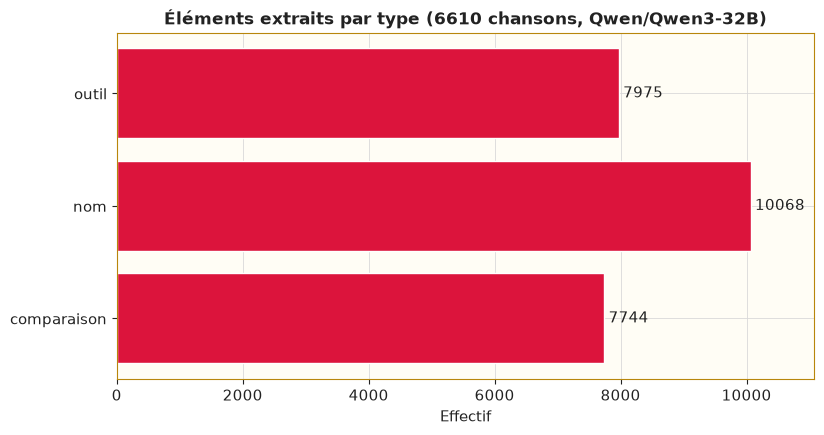

Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait3_stats_types_8861.png


In [8]:
types = stats_elements["type_element"].value_counts().reindex(["outil", "nom", "comparaison"], fill_value=0)
figure, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(types.index, types.values, color=PRINCIPAL, edgecolor=FOND)
ax.bar_label(ax.containers[0], padding=3)
ax.invert_yaxis()
ax.margins(x=0.10)
ax.set_title(f"Éléments extraits par type ({n_reussites} chansons, {modele})")
ax.set_xlabel("Effectif")
chemin_figure = images_dir / f"autoportrait3_stats_types_{len(selection)}.png"
figure.savefig(chemin_figure, dpi=150, bbox_inches="tight")
plt.show()
print("Figure :", chemin_figure)

### 5.2 Catégories les plus fréquentes

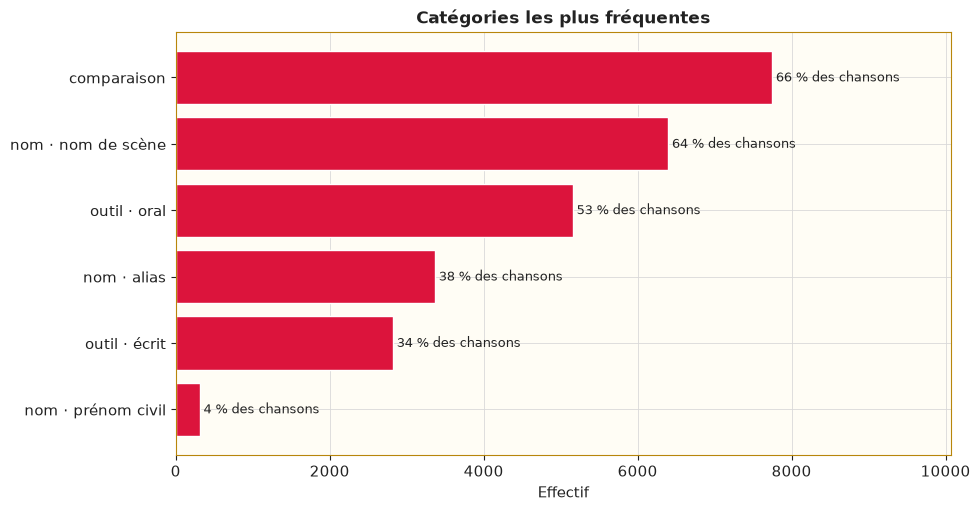

Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait3_stats_categories_8861.png


In [9]:
libelles_categories = {"nom_de_scene": "nom de scène", "prenom_civil": "prénom civil", "ecrit": "écrit"}
cats = stats_distributions.assign(
    libellé=lambda d: [f"{t} · {libelles_categories.get(c, c)}" if c else t
                       for t, c in zip(d["type_element"], d["categorie"])]
).sort_values("effectif").tail(10)
figure, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(cats["libellé"], cats["effectif"], color=PRINCIPAL, edgecolor=FOND)
for y, (effectif, pct) in enumerate(zip(cats["effectif"], cats["pourcentage_chansons"])):
    ax.text(effectif, y, f" {pct:.0f} % des chansons", va="center", fontsize=9)
ax.set_title("Catégories les plus fréquentes")
ax.set_xlabel("Effectif")
ax.margins(x=0.30)
chemin_figure = images_dir / f"autoportrait3_stats_categories_{len(selection)}.png"
figure.savefig(chemin_figure, dpi=150, bbox_inches="tight")
plt.show()
print("Figure :", chemin_figure)

### 5.3 Éléments par chanson

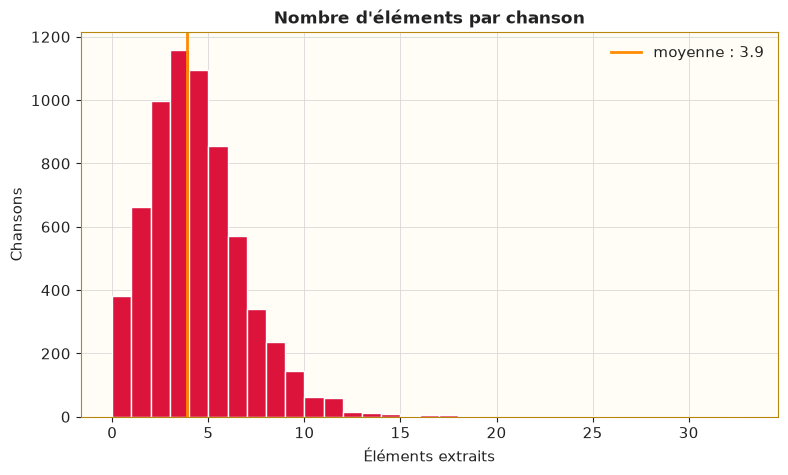

Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait3_stats_elements_par_chanson_8861.png


In [10]:
figure, ax = plt.subplots(figsize=(9, 5))
ax.hist(par_chanson, bins=range(0, int(par_chanson.max()) + 2), color=PRINCIPAL, edgecolor=FOND)
moyenne = float(par_chanson.mean())
ax.axvline(moyenne, color=ACCENT, linewidth=2, label=f"moyenne : {moyenne:.1f}")
ax.legend(frameon=False)
ax.set_title("Nombre d'éléments par chanson")
ax.set_xlabel("Éléments extraits")
ax.set_ylabel("Chansons")
chemin_figure = images_dir / f"autoportrait3_stats_elements_par_chanson_{len(selection)}.png"
figure.savefig(chemin_figure, dpi=150, bbox_inches="tight")
plt.show()
print("Figure :", chemin_figure)

### 5.4 Mentions

Nuage de mots des mentions citées plus de 50 fois.

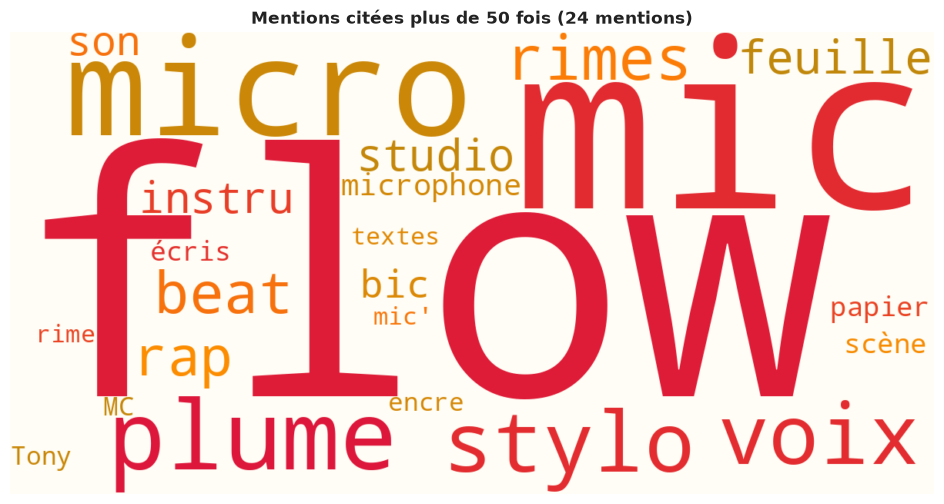

Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait3_stats_mentions_8861.png


In [12]:
from matplotlib.colors import LinearSegmentedColormap
from wordcloud import WordCloud

frequences_mentions = stats_elements["mention"].str.strip().value_counts()
mentions_frequentes = {m: int(n) for m, n in frequences_mentions.items() if m and n > 50}
cmap_hiphop = LinearSegmentedColormap.from_list("hiphop", [OR, ACCENT, PRINCIPAL])
nuage = WordCloud(width=1200, height=600, background_color=FOND_AXES, colormap=cmap_hiphop,
                  prefer_horizontal=1.0, random_state=0).generate_from_frequencies(mentions_frequentes)
figure, ax = plt.subplots(figsize=(12, 6))
ax.imshow(nuage, interpolation="bilinear")
ax.axis("off")
ax.set_title(f"Mentions citées plus de 50 fois ({len(mentions_frequentes)} mentions)")
chemin_figure = images_dir / f"autoportrait3_stats_mentions_{len(selection)}.png"
figure.savefig(chemin_figure, dpi=150, bbox_inches="tight")
plt.show()
print("Figure :", chemin_figure)

### 5.5 Références

Nuage de mots des références citées plus de 10 fois (comparaisons uniquement).

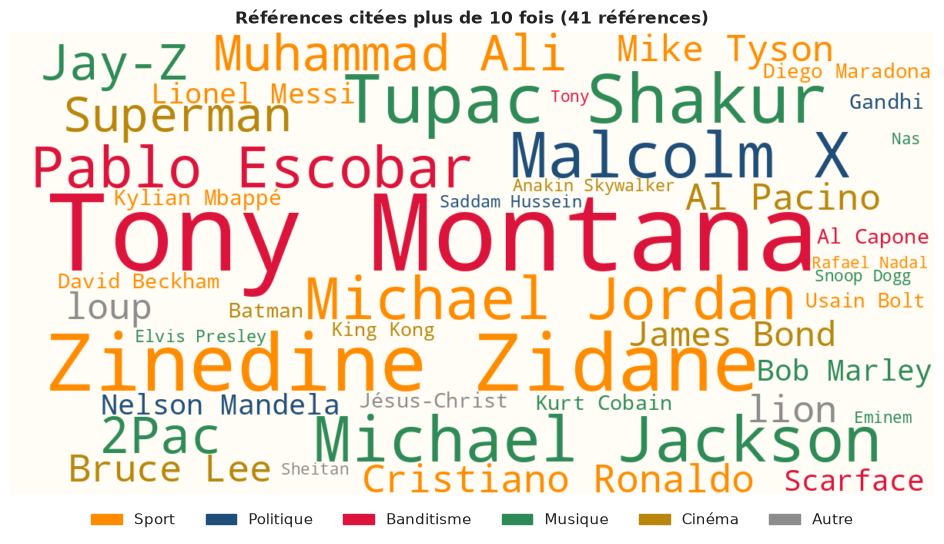

Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait3_stats_references_8861.png


In [15]:
frequences_references = stats_elements["reference"].str.strip().value_counts()
references_frequentes = {r: int(n) for r, n in frequences_references.items() if r and n > 10}
categories_personnages = {
    "Sport": ["Zinedine Zidane", "Michael Jordan", "Cristiano Ronaldo", "Mike Tyson", "Muhammad Ali",
              "Lionel Messi", "Kylian Mbappé", "Diego Maradona", "Usain Bolt", "David Beckham", "Rafael Nadal"],
    "Politique": ["Malcolm X", "Nelson Mandela", "Gandhi", "Saddam Hussein"],
    "Banditisme": ["Tony Montana", "Tony", "Pablo Escobar", "Al Capone", "Scarface"],
    "Musique": ["Tupac Shakur", "2Pac", "Michael Jackson", "Jay-Z", "Snoop Dogg", "Nas", "Eminem",
                "Kurt Cobain", "Bob Marley", "Elvis Presley"],
    "Cinéma": ["Al Pacino", "James Bond", "Batman", "Superman", "King Kong", "Anakin Skywalker", "Bruce Lee"]
}
categorie_par_reference = {ref: cat for cat, refs in categories_personnages.items() for ref in refs}
couleurs_categories = {"Sport": "#FF8C00", "Politique": "#1F4E79", "Banditisme": "#DC143C",
                       "Musique": "#2E8B57", "Cinéma": "#B8860B", "Autre": "#8C8C8C"}

def couleur_reference(mot, **_):
    return couleurs_categories[categorie_par_reference.get(mot, "Autre")]

nuage_references = WordCloud(width=1200, height=600, background_color=FOND_AXES,
                             prefer_horizontal=1.0, random_state=0,
                             color_func=couleur_reference).generate_from_frequencies(references_frequentes)
figure, ax = plt.subplots(figsize=(12, 6))
ax.imshow(nuage_references, interpolation="bilinear")
ax.axis("off")
ax.set_title(f"Références citées plus de 10 fois ({len(references_frequentes)} références)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in couleurs_categories.items()],
          loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=6, frameon=False)
chemin_figure = images_dir / f"autoportrait3_stats_references_{len(selection)}.png"
figure.savefig(chemin_figure, dpi=150, bbox_inches="tight")
plt.show()
print("Figure :", chemin_figure)

### 5.6 Références par catégorie

Même sélection que la 5.5 (références citées plus de 10 fois), avec un nuage de mots par catégorie. Les nuages partagent la même échelle de police : la taille d'un mot dépend de sa fréquence par rapport au maximum global.

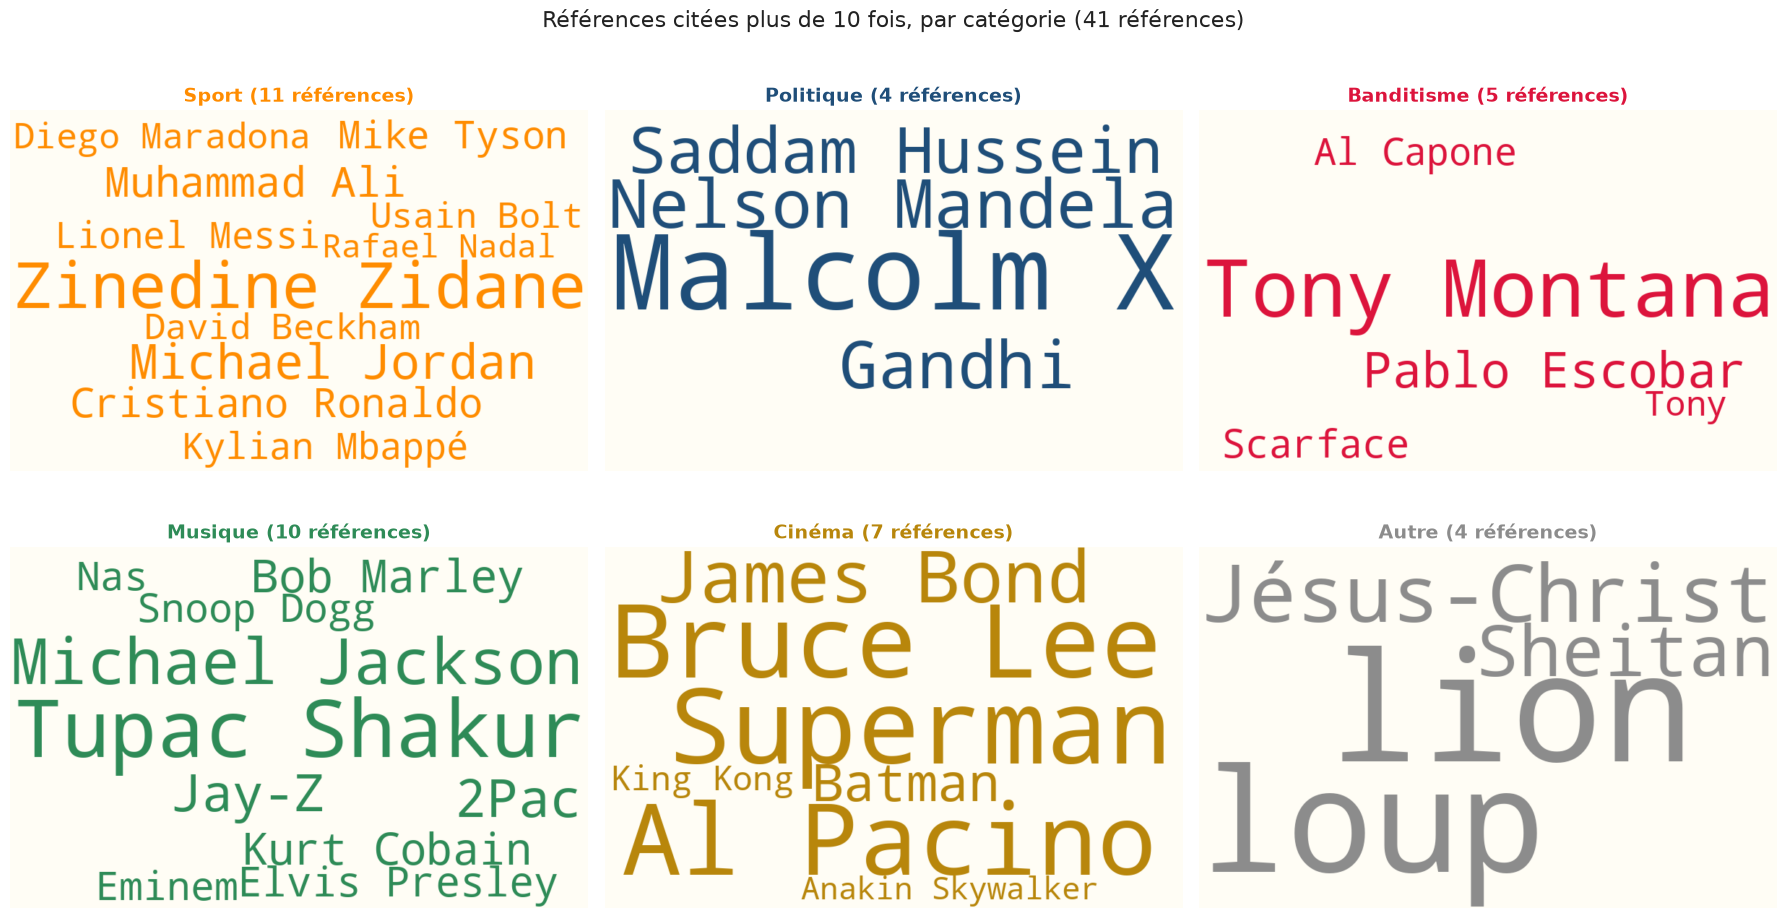

Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait3_stats_references_categories_8861.png


In [17]:
figure, axes = plt.subplots(2, 3, figsize=(18, 10))
freq_max_globale = max(references_frequentes.values())
ancre_echelle = " "  # mot invisible de fréquence maximale : WordCloud normalise chaque nuage sur son maximum
for ax, (categorie, couleur) in zip(axes.flat, couleurs_categories.items()):
    frequences_categorie = {r: n for r, n in references_frequentes.items()
                            if categorie_par_reference.get(r, "Autre") == categorie}
    frequences_avec_echelle = {ancre_echelle: freq_max_globale, **frequences_categorie}
    nuage_categorie = WordCloud(width=800, height=500, background_color=FOND_AXES,
                                prefer_horizontal=1.0, random_state=0, relative_scaling=0.5,
                                color_func=lambda mot, *_, c=couleur, **__: FOND_AXES if mot == ancre_echelle else c
                                ).generate_from_frequencies(frequences_avec_echelle)
    ax.imshow(nuage_categorie, interpolation="bilinear")
    ax.set_title(f"{categorie} ({len(frequences_categorie)} références)", color=couleur, fontsize=14)
    ax.axis("off")
figure.suptitle(f"Références citées plus de 10 fois, par catégorie ({len(references_frequentes)} références)", fontsize=16)
plt.tight_layout()
chemin_figure = images_dir / f"autoportrait3_stats_references_categories_{len(selection)}.png"
figure.savefig(chemin_figure, dpi=150, bbox_inches="tight")
plt.show()
print("Figure :", chemin_figure)